In [9]:
import numpy as np 
import matplotlib.pyplot as plt 

In [10]:
def f(x):
    return np.sin(x)

def df_true(x):
    return np.cos(x)

def deriv_forward(f,x,h):
    return (f(x+h) - f(x))/h

def deriv_central(f,x,h):
    return (f(x+h)-f(x-h))/(2*h)

x0 = 1.0

print("true",df_true(x0))
print("forward h=1e-5:",deriv_forward(f,x0,1e-5))
print("central h=1e-5:",deriv_central(f,x0,1e-5))


true 0.5403023058681398
forward h=1e-5: 0.5402980985058647
central h=1e-5: 0.5403023058569989


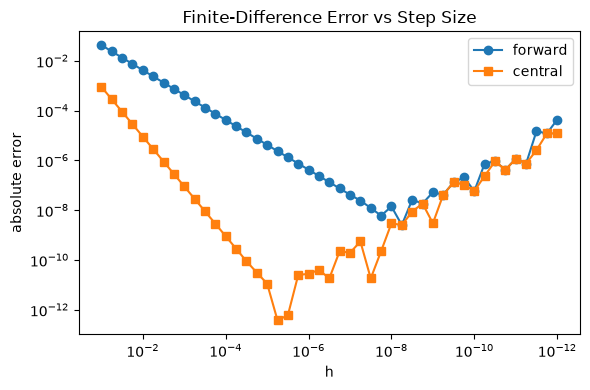

best h, forward: 5.623413251903491e-09
best h, central: 5.623413251903491e-06
Task 1 OK


In [11]:
hs = np.logspace(-1, -12, 45)
err_fwd = np.abs(deriv_forward(f, x0, hs) - df_true(x0))
err_ctr = np.abs(deriv_central(f, x0, hs) - df_true(x0))

plt.figure(figsize=(6, 4)) 
plt.loglog(hs, err_fwd, "o-", label="forward") 
plt.loglog(hs, err_ctr, "s-", label="central") 
plt.gca().invert_xaxis() 

plt.xlabel("h") 
plt.ylabel("absolute error") 
plt.legend() 
plt.title("Finite-Difference Error vs Step Size") 
plt.tight_layout() 
plt.show() 

print("best h, forward:", hs[np.argmin(err_fwd)]) 
print("best h, central:", hs[np.argmin(err_ctr)]) 

assert abs(deriv_central(f, x0, 1e-5) - df_true(x0)) < 1e-6 

print("Task 1 OK")

1. Which method gives a smaller error near its optimal h?
<p>The central-difference method. Its minimum error is around 10^(−10), while forward-difference reaches only 10^(-8).</p>


2. Why does the error eventually increase when h becomes extremely small?
<p>Round-off error. When h is too small f(x+h) and f(x) become almost identical. Subtracting them in Python loses floating-point precision.</p>

3. Why is the central-difference method generally more accurate than the forward-difference method?
<p>Better mathematical balance. It uses points on both sides (x+h and x−h) and first-order error terms cancel out (O(h^2) precision instead of O(h)).</p>